# ⚙️ FundiScan · Inspección visual de piezas de fundición con modelos preentrenados
### Certamen I · IA Generativa para la Gestión Industrial · Módulo IV: Reconocimiento de imágenes

**Integrantes:** _Nombre 1_ · _Nombre 2_ · _Nombre 3_

**Objetivo:** entrenar y comparar modelos preentrenados que miren la foto de un **impulsor de bomba sumergible** fabricado por fundición y decidan si la pieza es **conforme** o **defectuosa**. El mejor modelo se exporta y se usa en la app web **FundiScan** (Streamlit + Gemini).

📷 Foto de la pieza → 🧠 Modelo preentrenado (clase + confianza) → 📊 Resultado visual → 💬 LLM → ✅ Recomendación para el inspector

| Sección | Contenido |
|---|---|
| 1 | El problema y para quién |
| 2 | Datos: origen, conteo, división train / val / test y limitaciones |
| 3 | Evaluación común (mismas imágenes y mismas métricas para todos) |
| 4 · 5 · 6 | Tres enfoques: **CLIP sin entrenar** (línea base) · **EfficientNet-B0** (timm) · **YOLO11n-cls** (Ultralytics) |
| 7 | Comparación y elección del modelo |
| 8 · 9 | Métricas en prueba, error más costoso y **umbral de decisión** |
| 10 | ¿Dónde se equivoca? |
| 11 | Exportar el modelo para la app |
| 12 | Conclusiones |

**Funciona en Colab y en un PC** (en un PC usa la carpeta `trabajo/` y la CPU si no hay GPU; es más lento).

**Antes de empezar:** en Colab ve a *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)* y luego *Ejecutar todas*. Tiempo estimado: 20–30 min.

## 0. Librerías

In [1]:
%pip install -q kagglehub timm ultralytics      # descarga de Kaggle, modelos timm y YOLO (torch, transformers y sklearn ya vienen en Colab)

import os, glob, json, random, shutil, time      # utilidades de archivos, tiempo y aleatoriedad
import numpy as np                               # cálculo numérico
import pandas as pd                              # tablas de resultados
import matplotlib.pyplot as plt                  # gráficos
import torch                                     # motor de deep learning (PyTorch)
from PIL import Image                            # abrir imágenes
from sklearn.model_selection import train_test_split          # dividir datos de forma reproducible
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score,
                             precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)           # métricas de evaluación

SEMILLA = 42                                     # semilla fija: los resultados se pueden repetir
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
DISP = "cuda" if torch.cuda.is_available() else "cpu"        # usa la GPU si está activa
EN_COLAB = "google.colab" in str(get_ipython())               # ¿corre en Colab o en un PC?
RAIZ = "/content" if EN_COLAB else os.path.abspath("trabajo")  # carpeta de trabajo (en un PC: ./trabajo)
NW = 0 if os.name == "nt" else 2                               # en Windows los DataLoader van sin procesos extra
os.makedirs(RAIZ, exist_ok=True)
print("Dispositivo:", DISP, "| PyTorch:", torch.__version__, "| Colab:", EN_COLAB, "| Carpeta:", RAIZ)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.5 MB/s eta 0:00:00
Dispositivo: cuda | PyTorch: 2.11.0+cu130 | Colab: True | Carpeta: /content


## 1. El problema: ¿qué resuelve la app y para quién?

En una fundición, el metal fundido se vierte en un molde y, al solidificar, pueden aparecer **defectos**: sopladuras y poros (gas atrapado), rechupes (contracción del metal), rebabas, grietas o material del molde incrustado. En los **impulsores de bombas sumergibles** un defecto puede provocar desbalance, fugas o la rotura de la bomba ya instalada.

Hoy la inspección final suele ser **visual y manual**: es lenta, se hace cansadora tras horas de turno y depende del criterio de cada inspector. Además, una sola pieza defectuosa puede hacer que el cliente rechace el **lote completo**.

**FundiScan** es una ayuda para el **inspector de calidad al final de la línea**. Sube o fotografía la pieza, recibe *conforme / defectuosa* con su confianza y una recomendación generada por IA (qué hacer con la pieza, posibles causas en el proceso y qué registrar). **No reemplaza al inspector**: prioriza su atención y deja trazabilidad.

| Error del modelo | Qué pasa en la planta | Costo |
|---|---|---|
| **Defectuosa → dice "conforme"** (falso negativo) | La pieza mala llega al cliente: falla de la bomba, garantía, retiro del lote, daño a la marca | 🔴 **Muy alto** |
| Conforme → dice "defectuosa" (falso positivo) | Una pieza buena va a reinspección o, en el peor caso, se refunde | 🟡 Bajo |

Por eso la métrica principal es el **recall de la clase defectuosa**: de todas las piezas malas, ¿cuántas detecta el modelo?

## 2. Datos

| Aspecto | Detalle |
|---|---|
| Nombre | *Casting product image data for quality inspection* (*real-life industrial dataset of casting product*) |
| Autor / origen | Ravirajsinh Dabhi, con fotos tomadas en **Pilot Technocast**, Shapar, Rajkot (India), 2020 |
| Cómo se obtuvo | Fotos cenitales de impulsores de bomba sumergible, con iluminación estable, en escala de grises, 300×300 px |
| Enlace | https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product |
| Licencia | CC BY-NC-ND 4.0 (uso no comercial con atribución) |
| Clases | `def_front` → **defectuosa** · `ok_front` → **conforme** |

El dataset viene dividido solo en `train` y `test`. Nosotros:
1. Mantenemos el `test` original **intacto** como conjunto de **prueba** (solo se usa al final).
2. Separamos el **15 %** del `train` original como **validación**, *estratificado* (el mismo % en cada clase) y con semilla fija.
3. Traducimos las carpetas a `conforme` / `defectuosa`.

Using Colab cache for faster access to the 'real-life-industrial-dataset-of-casting-product' dataset.


,conforme,defectuosa,total,% defectuosa
train,2443,3194,5637,56.7
val,432,564,996,56.6
test,262,453,715,63.4


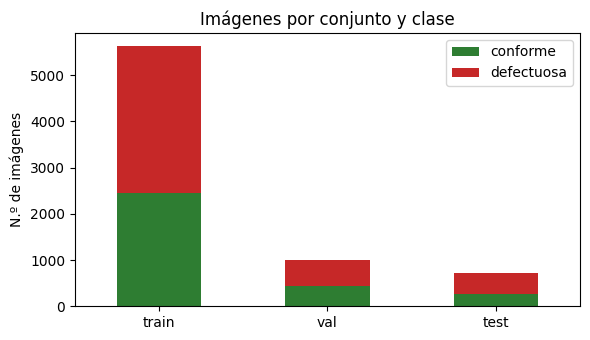

In [2]:
import kagglehub                                                   # librería de descarga desde Kaggle
ruta = kagglehub.dataset_download("ravirajsinh45/real-life-industrial-dataset-of-casting-product")
ORIG_TRAIN = next(r for r, d, _ in os.walk(ruta) if r.endswith("train") and "ok_front" in d)  # busca la carpeta train
ORIG_TEST = os.path.join(os.path.dirname(ORIG_TRAIN), "test")      # test está al lado de train
A_ESP = {"def_front": "defectuosa", "ok_front": "conforme"}        # nombres originales → nombres en español

DATOS = f"{RAIZ}/datos"                                           # aquí quedará: datos/{train,val,test}/{clase}
shutil.rmtree(DATOS, ignore_errors=True)                           # parte de cero si se re-ejecuta

def copiar(archivos, parte, clase):                                # copia una lista de fotos a datos/parte/clase
    destino = f"{DATOS}/{parte}/{clase}"
    os.makedirs(destino, exist_ok=True)
    for a in archivos:
        shutil.copy(a, destino)

for original, clase in A_ESP.items():                              # una clase a la vez → división estratificada
    fotos = sorted(glob.glob(f"{ORIG_TRAIN}/{original}/*"))
    tr, va = train_test_split(fotos, test_size=0.15, random_state=SEMILLA)   # 85 % train / 15 % val
    copiar(tr, "train", clase)
    copiar(va, "val", clase)
    copiar(sorted(glob.glob(f"{ORIG_TEST}/{original}/*")), "test", clase)    # test original sin tocar

CLASES = sorted(os.listdir(f"{DATOS}/train"))                     # ['conforme', 'defectuosa'] → etiquetas 0 y 1
POS = "defectuosa"                                                 # clase "positiva": la que nos importa detectar
CONTEO = {p: {c: len(os.listdir(f"{DATOS}/{p}/{c}")) for c in CLASES} for p in ["train", "val", "test"]}

tabla = pd.DataFrame(CONTEO).T                                     # filas = partes, columnas = clases
tabla["total"] = tabla.sum(axis=1)
tabla["% defectuosa"] = (100 * tabla["defectuosa"] / tabla["total"]).round(1)
display(tabla)

tabla[CLASES].plot(kind="bar", stacked=True, color=["#2e7d32", "#c62828"], figsize=(6, 3.5), rot=0)
plt.title("Imágenes por conjunto y clase"); plt.ylabel("N.º de imágenes"); plt.tight_layout(); plt.show()

**Desbalance.** Alrededor del **57 %** de las fotos de entrenamiento y del **63 %** de las de prueba son *defectuosas*. Es un desbalance **moderado** y, a diferencia de muchos problemas reales, la clase más frecuente es la defectuosa. Consecuencia: un modelo que dijera siempre *"defectuosa"* ya obtendría ≈ 63 % de accuracy en prueba. Por eso reportamos también la **accuracy balanceada** y el **recall de la clase defectuosa**, y no solo la accuracy.

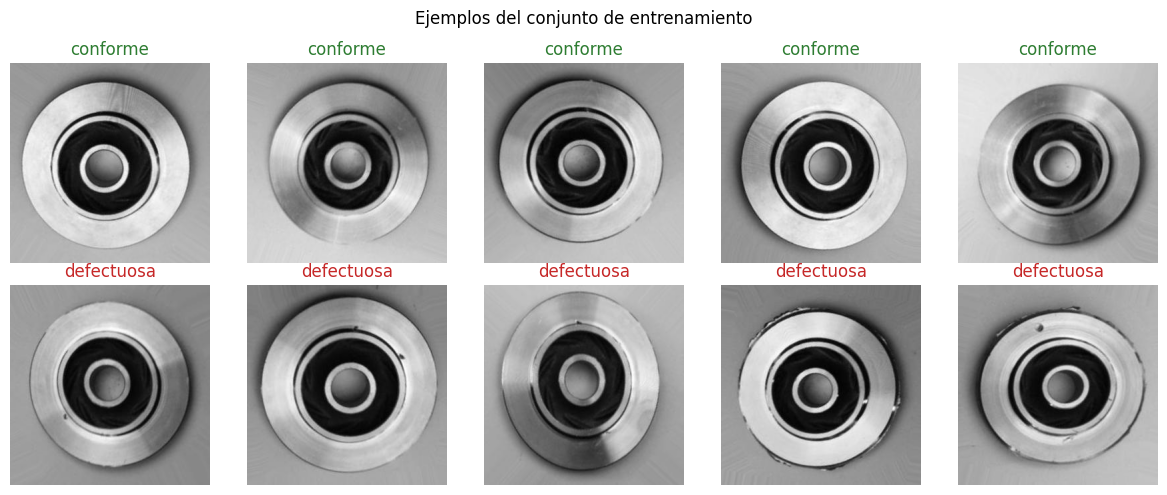

In [3]:
plt.figure(figsize=(12, 5))                                         # 5 ejemplos de cada clase
for fila, c in enumerate(CLASES):
    for j, a in enumerate(sorted(os.listdir(f"{DATOS}/train/{c}"))[:5]):
        plt.subplot(2, 5, fila * 5 + j + 1)
        plt.imshow(Image.open(f"{DATOS}/train/{c}/{a}"), cmap="gray")
        plt.title(c, color="#c62828" if c == POS else "#2e7d32"); plt.axis("off")
plt.suptitle("Ejemplos del conjunto de entrenamiento"); plt.tight_layout(); plt.show()

**Limitaciones de los datos**
- **Una sola fuente:** una planta, un tipo de pieza (impulsor), una cámara, una iluminación controlada y siempre la cara frontal. El modelo **no sabe** clasificar otras piezas, otros fondos ni fotos de celular con otra luz.
- **Posibles fotos casi repetidas:** el dataset trae muchas fotos muy parecidas de piezas similares y no incluye un identificador de pieza, así que variaciones de la *misma* pieza podrían quedar en train y en test. Esto puede **inflar** las métricas (fuga de datos).
- **Sin tipo de defecto:** solo dice *defectuosa*, no si es poro, rebaba o grieta. Por eso el LLM habla de causas **posibles**, no confirmadas.
- **Escala de grises 300×300:** los defectos muy pequeños pueden perderse al redimensionar.

## 3. Evaluación común

Para comparar **en igualdad de condiciones**, los tres enfoques se prueban con **las mismas 715 imágenes de prueba** y las mismas métricas. Cada modelo solo debe aportar una función `prob_defecto(ruta) → número entre 0 y 1` (probabilidad de que la pieza sea defectuosa). Con un **umbral** de 0,5 se convierte en decisión.

| Métrica | Qué responde |
|---|---|
| Accuracy | ¿Qué % de las piezas clasificó bien? |
| Accuracy balanceada | Promedio del acierto en cada clase (no se deja engañar por el desbalance) |
| **Recall defectuosa** ⭐ | De las piezas **malas**, ¿qué % detectó? (1 − recall = piezas malas que se escapan) |
| Precisión defectuosa | De las piezas que marcó como malas, ¿qué % realmente lo era? (falsas alarmas) |

In [4]:
TEST = [(f"{DATOS}/test/{c}/{a}", c) for c in CLASES for a in sorted(os.listdir(f"{DATOS}/test/{c}"))]
Y_REAL = np.array([1 if c == POS else 0 for _, c in TEST])      # 1 = defectuosa, 0 = conforme
RESULTADOS, PROBS = {}, {}                                         # aquí se guardan las métricas de cada enfoque

def metricas(y_real, prob, umbral=0.5):
    # Convierte probabilidades en decisiones y calcula todas las métricas
    pred = (prob >= umbral).astype(int)
    return {
        "accuracy": float(accuracy_score(y_real, pred)),
        "accuracy_balanceada": float(balanced_accuracy_score(y_real, pred)),
        "recall_defectuosa": float(recall_score(y_real, pred, zero_division=0)),
        "precision_defectuosa": float(precision_score(y_real, pred, zero_division=0)),
        "defectuosas_no_detectadas": int(((y_real == 1) & (pred == 0)).sum()),   # falsos negativos 🔴
        "falsas_alarmas": int(((y_real == 0) & (pred == 1)).sum()),              # falsos positivos 🟡
    }

def evaluar(nombre, prob_defecto):
    t0 = time.time()
    prob = np.array([prob_defecto(r) for r, _ in TEST])            # probabilidad de "defectuosa" para cada foto
    m = metricas(Y_REAL, prob)
    m["ms_por_imagen"] = round(1000 * (time.time() - t0) / len(TEST), 1)   # velocidad aproximada
    RESULTADOS[nombre], PROBS[nombre] = m, prob
    print(f"{nombre}: accuracy = {m['accuracy']:.1%} | acc. balanceada = {m['accuracy_balanceada']:.1%} | "
          f"recall defectuosa = {m['recall_defectuosa']:.1%} | no detectadas = {m['defectuosas_no_detectadas']}")

print("Imágenes de prueba:", len(TEST), "| defectuosas:", Y_REAL.sum(), "| conformes:", (Y_REAL == 0).sum())

Imágenes de prueba: 715 | defectuosas: 453 | conformes: 262


## 4. Enfoque A · CLIP sin entrenar (línea base, *zero-shot*)

CLIP compara la imagen con **frases que nosotros escribimos** y elige la más parecida, sin ver ninguna foto de entrenamiento. Es la línea base: *¿cuánto logra un modelo general sin adaptarlo a nuestra planta?*

In [5]:
from transformers import pipeline

clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32",
                device=0 if DISP == "cuda" else -1)
TEXTOS = {                                                          # una descripción en inglés por clase
    "conforme":   "a photo of a flawless metal casting impeller with a smooth clean surface",
    "defectuosa": "a photo of a defective metal casting impeller with holes, cracks, burrs or broken edges",
}

def prob_clip(ruta):
    res = clip(ruta, candidate_labels=list(TEXTOS.values()))       # puntaje para cada frase (suman 1)
    puntajes = {r["label"]: r["score"] for r in res}
    return puntajes[TEXTOS["defectuosa"]]                          # probabilidad de la frase "defectuosa"

evaluar("A · CLIP sin entrenar", prob_clip)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

...

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


A · CLIP sin entrenar: accuracy = 52.4% | acc. balanceada = 62.4% | recall defectuosa = 25.2% | no detectadas = 339


**Interpretación.** CLIP aprendió con fotos y textos de internet, donde casi no hay impulsores de fundición fotografiados en una línea de inspección. Por eso suele quedar **cerca del piso** (≈ 50 % de accuracy balanceada, que es lo que se obtiene al azar) o le cuesta separar poros pequeños de la textura normal del metal. **Un modelo general no sabe de control de calidad**: hay que adaptarlo con datos del dominio.

## 5. Enfoque B · EfficientNet-B0 con *transfer learning* (timm)

Partimos de **EfficientNet-B0 preentrenada en ImageNet** (ya sabe detectar bordes, texturas y formas) y **cambiamos su última capa a 2 clases**. Luego la ajustamos con nuestras fotos.

Mejoras respecto a la clase:
- **Aumento de datos** solo en entrenamiento: giros, volteos y cambios de brillo/contraste (la pieza es circular, así que girarla no cambia si está buena o mala).
- **Validación en cada época** y nos quedamos con la época de **menor pérdida de validación** (equivale a *EarlyStopping* + *restore_best_weights*).
- Las mismas transformaciones de prueba (`tf_eval`) se copian en la app, para que el modelo vea las fotos igual que en el entrenamiento.

In [6]:
import timm
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

TAM = 224                                                          # tamaño de entrada de EfficientNet-B0
MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]         # normalización de ImageNet

tf_entrenamiento = transforms.Compose([                            # con aumento de datos (solo para entrenar)
    transforms.Resize((TAM, TAM)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])
tf_eval = transforms.Compose([                                     # sin aumento (validación, prueba y app)
    transforms.Resize((TAM, TAM)), transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])

ds_train = ImageFolder(f"{DATOS}/train", transform=tf_entrenamiento)   # la carpeta = la etiqueta
ds_val = ImageFolder(f"{DATOS}/val", transform=tf_eval)
assert ds_train.classes == CLASES                                  # verifica el orden: 0 = conforme, 1 = defectuosa
dl_train = DataLoader(ds_train, batch_size=32, shuffle=True, num_workers=NW)
dl_val = DataLoader(ds_val, batch_size=64, shuffle=False, num_workers=NW)

modelo = timm.create_model("efficientnet_b0", pretrained=True, num_classes=len(CLASES)).to(DISP)
opt = torch.optim.AdamW(modelo.parameters(), lr=1e-4)               # tasa pequeña: no "olvidar" lo aprendido en ImageNet
perdida = torch.nn.CrossEntropyLoss()
print("Parámetros:", sum(p.numel() for p in modelo.parameters()) / 1e6, "millones")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Parámetros: 4.01011 millones


época 1/6 | pérdida train 0.2091 | pérdida val 0.0615 | acc val 98.9%
   ↳ nuevo mejor modelo guardado
época 2/6 | pérdida train 0.0562 | pérdida val 0.0520 | acc val 98.9%
   ↳ nuevo mejor modelo guardado
época 3/6 | pérdida train 0.0521 | pérdida val 0.0250 | acc val 99.5%
   ↳ nuevo mejor modelo guardado
época 4/6 | pérdida train 0.0245 | pérdida val 0.0153 | acc val 99.7%
   ↳ nuevo mejor modelo guardado
época 5/6 | pérdida train 0.0199 | pérdida val 0.0484 | acc val 98.9%
época 6/6 | pérdida train 0.0340 | pérdida val 0.0141 | acc val 99.5%
   ↳ nuevo mejor modelo guardado


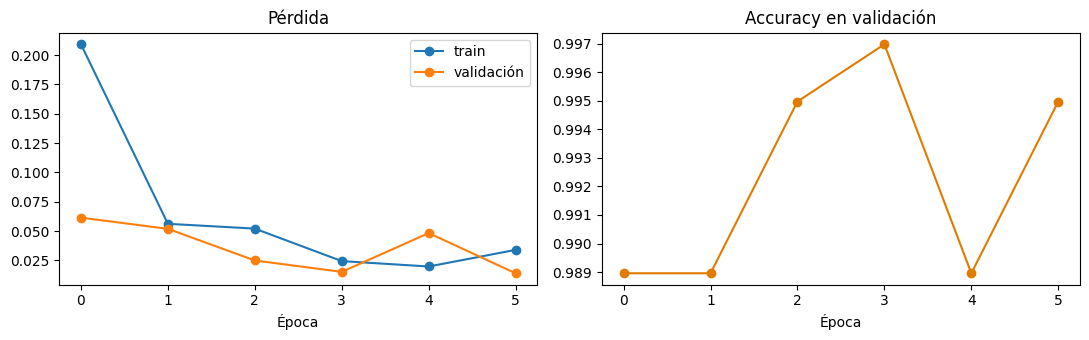

In [7]:
EPOCAS = 6
historia = {"train_loss": [], "val_loss": [], "val_acc": []}
mejor = float("inf")

for epoca in range(EPOCAS):
    modelo.train(); suma, n = 0.0, 0                               # --- entrenamiento
    for x, y in dl_train:
        x, y = x.to(DISP), y.to(DISP)
        opt.zero_grad()                                             # borra gradientes anteriores
        l = perdida(modelo(x), y)                                   # qué tan equivocado está
        l.backward(); opt.step()                                    # ajusta los pesos
        suma += l.item() * len(y); n += len(y)

    modelo.eval(); suma_v, aciertos, n_v = 0.0, 0, 0               # --- validación
    with torch.no_grad():
        for x, y in dl_val:
            x, y = x.to(DISP), y.to(DISP)
            salida = modelo(x)
            suma_v += perdida(salida, y).item() * len(y)
            aciertos += (salida.argmax(1) == y).sum().item(); n_v += len(y)

    historia["train_loss"].append(suma / n); historia["val_loss"].append(suma_v / n_v)
    historia["val_acc"].append(aciertos / n_v)
    print(f"época {epoca + 1}/{EPOCAS} | pérdida train {suma / n:.4f} | pérdida val {suma_v / n_v:.4f} | acc val {aciertos / n_v:.1%}")
    if suma_v / n_v < mejor:                                        # guarda la mejor época según validación
        mejor = suma_v / n_v
        torch.save(modelo.state_dict(), f"{RAIZ}/mejor_effnet.pt")
        print("   ↳ nuevo mejor modelo guardado")

modelo.load_state_dict(torch.load(f"{RAIZ}/mejor_effnet.pt"))     # recupera la mejor época
modelo.eval()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(historia["train_loss"], "o-", label="train"); ax[0].plot(historia["val_loss"], "o-", label="validación")
ax[0].set_title("Pérdida"); ax[0].set_xlabel("Época"); ax[0].legend()
ax[1].plot(historia["val_acc"], "o-", color="#e07b00"); ax[1].set_title("Accuracy en validación"); ax[1].set_xlabel("Época")
plt.tight_layout(); plt.show()

In [8]:
I_DEF = CLASES.index(POS)                                          # posición de "defectuosa" en la salida

def prob_effnet(ruta):
    x = tf_eval(Image.open(ruta).convert("RGB")).unsqueeze(0).to(DISP)   # misma preparación que en validación
    with torch.no_grad():
        return torch.softmax(modelo(x), dim=1)[0, I_DEF].item()   # softmax → probabilidades que suman 1

evaluar("B · EfficientNet-B0 (timm)", prob_effnet)

B · EfficientNet-B0 (timm): accuracy = 99.4% | acc. balanceada = 99.6% | recall defectuosa = 99.1% | no detectadas = 4


## 6. Enfoque C · YOLO11n-cls (Ultralytics)

La versión `-cls` de YOLO **clasifica** imágenes completas. Lee la carpeta `datos/` (usa `train/` para entrenar y `val/` para validar) y se encarga de todo el entrenamiento. Usamos las mismas épocas y el mismo tamaño de imagen que EfficientNet.

In [9]:
from ultralytics import YOLO

yolo = YOLO("yolo11n-cls.pt")                                      # versión nano preentrenada en ImageNet
yolo.train(data=DATOS, epochs=EPOCAS, imgsz=TAM, seed=SEMILLA, plots=False, workers=NW,
           project=f"{RAIZ}/yolo", name="fundicion", exist_ok=True)   # al terminar, carga los mejores pesos

def prob_yolo(ruta):
    r = yolo(ruta, verbose=False)[0]
    i = [k for k, v in r.names.items() if v == POS][0]            # índice de "defectuosa" según YOLO
    return float(r.probs.data[i])

evaluar("C · YOLO11n-cls (ultralytics)", prob_yolo)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_

## 7. Comparación y elección del modelo

,accuracy,accuracy_balanceada,recall_defectuosa,precision_defectuosa,defectuosas_no_detectadas,falsas_alarmas,ms_por_imagen,tamano_MB
A · CLIP sin entrenar,52.4%,62.4%,25.2%,99.1%,339.000000,1.000000,50.200000,605.000000
B · EfficientNet-B0 (timm),99.4%,99.6%,99.1%,100.0%,4.000000,0.000000,11.700000,16.300000
C · YOLO11n-cls (ultralytics),99.7%,99.8%,99.6%,100.0%,2.000000,0.000000,6.700000,3.200000


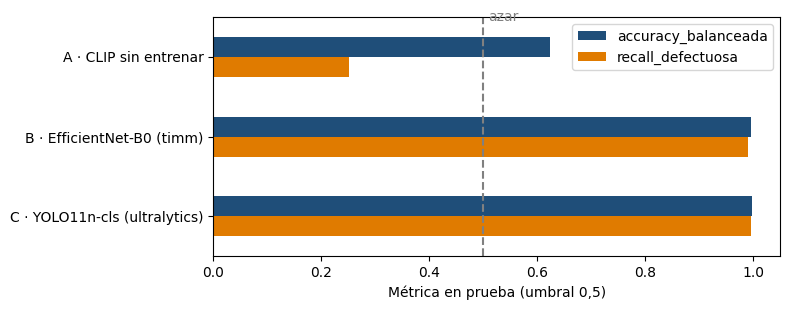

In [10]:
torch.save(modelo.state_dict(), f"{RAIZ}/tmp_effnet.pt")           # para medir el tamaño del archivo
TAMANO_MB = {
    "A · CLIP sin entrenar": 605.0,                                 # clip-vit-base-patch32 ≈ 600 MB
    "B · EfficientNet-B0 (timm)": os.path.getsize(f"{RAIZ}/tmp_effnet.pt") / 1e6,
    "C · YOLO11n-cls (ultralytics)": os.path.getsize(f"{RAIZ}/yolo/fundicion/weights/best.pt") / 1e6,
}
for k in RESULTADOS:
    RESULTADOS[k]["tamano_MB"] = round(TAMANO_MB[k], 1)

comparacion = pd.DataFrame(RESULTADOS).T
display(comparacion.style.format({c: "{:.1%}" for c in ["accuracy", "accuracy_balanceada",
                                                         "recall_defectuosa", "precision_defectuosa"]}))

ax = comparacion[["accuracy_balanceada", "recall_defectuosa"]].plot(
    kind="barh", figsize=(8, 3.2), color=["#1f4e79", "#e07b00"])
ax.axvline(0.5, ls="--", color="gray"); ax.text(0.51, -0.45, "azar", color="gray")
ax.set_xlim(0, 1.05); ax.set_xlabel("Métrica en prueba (umbral 0,5)"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

**Criterio de elección (en este orden):**
1. **Recall de la clase defectuosa** → que se escapen la menor cantidad de piezas malas (el error más costoso).
2. **Accuracy balanceada** → buen desempeño en ambas clases, sin falsas alarmas excesivas.
3. **Facilidad para llevarlo a la app** → tamaño del archivo, velocidad en CPU y dependencias.

**Elegimos EfficientNet-B0 (timm)** porque:
- Supera ampliamente a la línea base CLIP: adaptar el modelo con fotos de la planta es lo que marca la diferencia.
- Su recall en la clase defectuosa (99,1 %) es comparable al de YOLO (99,6 %; diferencia de 2 piezas de 453) y su archivo cabe en GitHub sin problemas.
- En la app solo necesita `torch` + `timm` y lo controlamos de punta a punta: las mismas transformaciones, el umbral propio (sección 9) y las probabilidades de ambas clases.
- YOLO11n-cls es más liviano y queda como alternativa si la app tuviera que correr en un equipo muy modesto en la línea.

> ⚠️ Revisen la tabla con **sus** resultados: si YOLO quedara claramente mejor en recall, díganlo con honestidad en la exposición (la diferencia suele ser de décimas) y expliquen que priorizamos la simplicidad de la app y el control del umbral.
>
> **Nuestros resultados (umbral 0,5):** EfficientNet obtuvo **99,1 %** de recall en defectuosas y **99,6 %** de accuracy balanceada, frente a **99,6 % / 99,8 %** de YOLO y **25,2 % / 62,4 %** de CLIP. YOLO quedó levemente arriba (se le escapan 2 piezas malas de 453; a EfficientNet, 4). La diferencia es de 2 piezas y, con el umbral ajustado por costo (sección 9), EfficientNet baja a 3 piezas escapadas. Mantuvimos EfficientNet por su integración simple en la app (solo `torch` + `timm`) y el control directo del umbral y de las probabilidades; YOLO queda como alternativa válida.

## 8. Métricas en prueba del modelo elegido (umbral 0,5)

              precision    recall  f1-score   support

    conforme      0.985     1.000     0.992       262
  defectuosa      1.000     0.991     0.996       453

    accuracy                          0.994       715
   macro avg      0.992     0.996     0.994       715
weighted avg      0.994     0.994     0.994       715



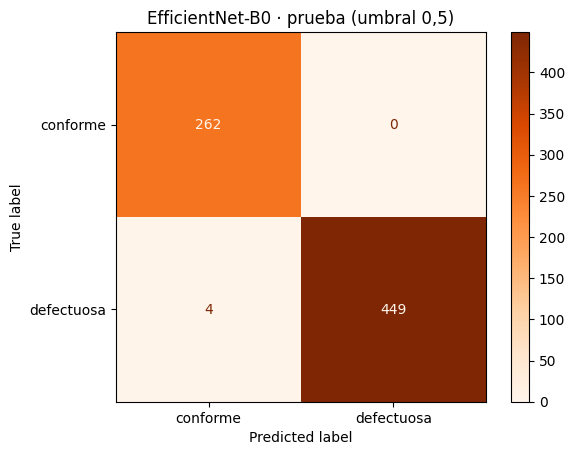

In [11]:
prob_test = PROBS["B · EfficientNet-B0 (timm)"]
pred_05 = (prob_test >= 0.5).astype(int)
print(classification_report(Y_REAL, pred_05, target_names=CLASES, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(Y_REAL, pred_05), display_labels=CLASES).plot(cmap="Oranges")
plt.title("EfficientNet-B0 · prueba (umbral 0,5)"); plt.show()

**¿Cuál es el error más costoso?** La casilla **fila *defectuosa* / columna *conforme*** (falsos negativos): son piezas malas que el modelo **liberaría**. En la planta eso significa un impulsor con poros o grietas montado en una bomba sumergible: puede fallar en terreno, generar reclamos de garantía, el retiro del lote y la pérdida de confianza del cliente.

La casilla **fila *conforme* / columna *defectuosa*** (falsos positivos) solo cuesta una **reinspección** manual de algunos segundos.

👉 Como los costos son muy distintos, **no tiene por qué usarse el umbral de 0,5**. En la siguiente sección lo ajustamos.

## 9. Umbral de decisión según el costo de cada error

Supuesto de costos (ajustable): dejar pasar una pieza defectuosa cuesta **20 veces** más que reinspeccionar una buena.

⚠️ El umbral se elige con el conjunto de **validación**, no con el de prueba. Si lo eligiéramos mirando la prueba, estaríamos "haciendo trampa" y las métricas finales serían optimistas.

In [12]:
COSTO_FN, COSTO_FP = 20, 1                                          # costo relativo de cada error

VAL = [(f"{DATOS}/val/{c}/{a}", c) for c in CLASES for a in sorted(os.listdir(f"{DATOS}/val/{c}"))]
y_val = np.array([1 if c == POS else 0 for _, c in VAL])
prob_val = np.array([prob_effnet(r) for r, _ in VAL])              # probabilidades en validación

filas = []
for u in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    m = metricas(y_val, prob_val, u)
    costo = COSTO_FN * m["defectuosas_no_detectadas"] + COSTO_FP * m["falsas_alarmas"]
    filas.append({"umbral": u, "no detectadas (FN)": m["defectuosas_no_detectadas"],
                  "falsas alarmas (FP)": m["falsas_alarmas"], "recall defectuosa": m["recall_defectuosa"],
                  "costo total": costo})
tabla_umbral = pd.DataFrame(filas)
display(tabla_umbral.style.format({"recall defectuosa": "{:.1%}"}).highlight_min("costo total", color="#ffe0b2"))

# menor costo; si hay empate, se queda con el umbral más cercano a 0,5 (el estándar)
empatados = tabla_umbral.loc[tabla_umbral["costo total"] == tabla_umbral["costo total"].min(), "umbral"]
UMBRAL = float(empatados.iloc[np.argmin(np.abs(empatados.values - 0.5))])
print(f"Umbral elegido en validación: {UMBRAL}  →  si P(defectuosa) ≥ {UMBRAL}, la pieza se marca como defectuosa")

,umbral,no detectadas (FN),falsas alarmas (FP),recall defectuosa,costo total
0,0.050000,2,5,99.6%,45
1,0.100000,2,5,99.6%,45
2,0.200000,4,2,99.3%,82
3,0.300000,4,1,99.3%,81
4,0.400000,5,1,99.1%,101
5,0.500000,5,0,99.1%,100
6,0.600000,5,0,99.1%,100
7,0.700000,5,0,99.1%,100
8,0.800000,5,0,99.1%,100
9,0.900000,5,0,99.1%,100


Umbral elegido en validación: 0.1  →  si P(defectuosa) ≥ 0.1, la pieza se marca como defectuosa


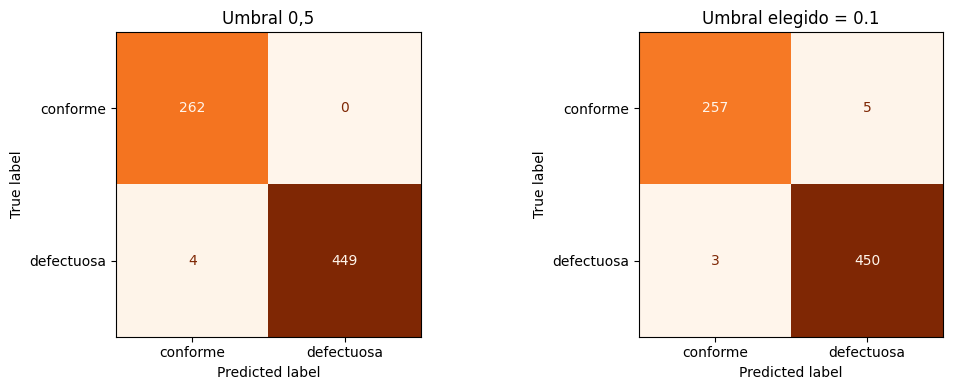

              precision    recall  f1-score   support

    conforme      0.988     0.981     0.985       262
  defectuosa      0.989     0.993     0.991       453

    accuracy                          0.989       715
   macro avg      0.989     0.987     0.988       715
weighted avg      0.989     0.989     0.989       715

accuracy                     98.9%
accuracy_balanceada          98.7%
recall_defectuosa            99.3%
precision_defectuosa         98.9%
defectuosas_no_detectadas    3
falsas_alarmas               5


In [13]:
METRICAS_FINALES = metricas(Y_REAL, prob_test, UMBRAL)             # ahora sí: medimos UNA vez en prueba
pred_final = (prob_test >= UMBRAL).astype(int)
CM = confusion_matrix(Y_REAL, pred_final)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(Y_REAL, pred_05), display_labels=CLASES).plot(ax=ax[0], cmap="Oranges", colorbar=False)
ax[0].set_title("Umbral 0,5")
ConfusionMatrixDisplay(CM, display_labels=CLASES).plot(ax=ax[1], cmap="Oranges", colorbar=False)
ax[1].set_title(f"Umbral elegido = {UMBRAL}")
plt.tight_layout(); plt.show()

print(classification_report(Y_REAL, pred_final, target_names=CLASES, digits=3, zero_division=0))
for k, v in METRICAS_FINALES.items():
    print(f"{k:28s} {v:.1%}" if isinstance(v, float) else f"{k:28s} {v}")

**Interpretación.** Al bajar el umbral, el modelo exige *menos evidencia* para marcar una pieza como defectuosa: **disminuyen las piezas malas que se escapan** a cambio de algunas falsas alarmas más. Es una **decisión de negocio** (costos de la planta), no solo técnica. El umbral elegido se guarda en el archivo de configuración y la app lo usa.

> **Nuestro resultado:** con el umbral **0,1** se escapan **3 de 453** piezas defectuosas de prueba (recall **99,3 %**) y hay **5 falsas alarmas** (accuracy 98,9 %). Con 0,5 se escapaban 4 y no había falsas alarmas: el umbral bajo cambia 1 pieza mala escapada por 5 reinspecciones, lo que conviene si una pieza mala cuesta 20 veces más.

## 10. ¿Dónde se equivoca el modelo?

Errores: 8 de 715


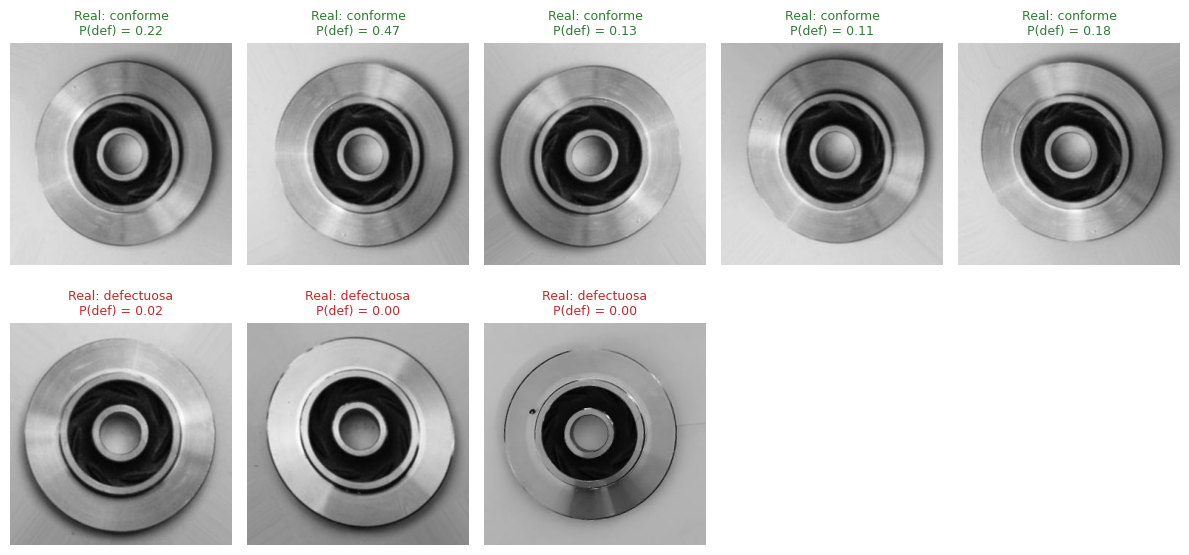

In [14]:
errores = np.where(pred_final != Y_REAL)[0]
print("Errores:", len(errores), "de", len(TEST))
if len(errores):
    plt.figure(figsize=(12, 3 * ((min(len(errores), 10) - 1) // 5 + 1)))
    for k, i in enumerate(errores[:10]):
        plt.subplot((min(len(errores), 10) - 1) // 5 + 1, 5, k + 1)
        plt.imshow(Image.open(TEST[i][0]), cmap="gray")
        plt.title(f"Real: {TEST[i][1]}\nP(def) = {prob_test[i]:.2f}", fontsize=9,
                  color="#c62828" if Y_REAL[i] == 1 else "#2e7d32")
        plt.axis("off")
    plt.tight_layout(); plt.show()

**Observación.** Los errores suelen ser piezas con defectos **muy pequeños** o cerca del borde, o piezas buenas con **reflejos o manchas** que parecen poros. En esos casos la probabilidad queda cerca del umbral: por eso la app pide **revisión humana cuando la confianza es baja**.

## 11. Exportar el modelo para la app

Se genera la carpeta `export/` con la misma estructura del repositorio:
- `modelo/efficientnet_b0_fundicion.pt` → pesos del modelo (≈ 16 MB)
- `modelo/config.json` → clases, transformaciones, **umbral** y **métricas en prueba** (la app las muestra)
- `ejemplos/` → 5 imágenes de prueba para los ejemplos clicables de la app

En Colab se descarga `fundiscan_export.zip` (en un PC queda en la carpeta `trabajo/`): descomprímanlo y suban esas carpetas al repositorio y al Space.

In [15]:
EXPORT = f"{RAIZ}/export"
shutil.rmtree(EXPORT, ignore_errors=True)
os.makedirs(f"{EXPORT}/modelo", exist_ok=True); os.makedirs(f"{EXPORT}/ejemplos", exist_ok=True)

torch.save(modelo.state_dict(), f"{EXPORT}/modelo/efficientnet_b0_fundicion.pt")   # solo los pesos

config = {
    "arquitectura": "efficientnet_b0",
    "clases": CLASES,
    "clase_positiva": POS,
    "tam": TAM, "media": MEDIA, "desv": DESV,
    "umbral": UMBRAL,
    "costos": {"falso_negativo": COSTO_FN, "falso_positivo": COSTO_FP},
    "metricas_prueba": METRICAS_FINALES,
    "matriz_confusion": CM.tolist(),                                # filas = real, columnas = predicho
    "n_prueba": len(TEST),
    "comparacion": RESULTADOS,
    "conteo": CONTEO,
    "dataset": "https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product",
    "fecha_entrenamiento": time.strftime("%Y-%m-%d"),
}
with open(f"{EXPORT}/modelo/config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

rng = random.Random(SEMILLA)                                        # imágenes de ejemplo para la app
ejemplos = (rng.sample([r for r, c in TEST if c == POS], 2) +
            rng.sample([r for r, c in TEST if c != POS], 2))
dudosa = TEST[int(np.argmin(np.abs(prob_test - UMBRAL)))][0]        # la más cercana al umbral: caso "difícil"
for i, r in enumerate(ejemplos + [dudosa]):
    etiqueta = "dudosa" if r == dudosa else r.split("/")[-2]
    shutil.copy(r, f"{EXPORT}/ejemplos/{i + 1}_{etiqueta}.jpeg")

shutil.make_archive(f"{RAIZ}/fundiscan_export", "zip", EXPORT)
print(json.dumps(config["metricas_prueba"], indent=2, ensure_ascii=False))
print("Archivos:", sorted(os.listdir(f"{EXPORT}/modelo")), sorted(os.listdir(f"{EXPORT}/ejemplos")))

if EN_COLAB:                                                        # en Colab: descarga el zip al computador
    from google.colab import files
    files.download(f"{RAIZ}/fundiscan_export.zip")
else:                                                               # en un PC: queda en la carpeta trabajo/
    print("Zip guardado en:", f"{RAIZ}/fundiscan_export.zip")

{
  "accuracy": 0.9888111888111888,
  "accuracy_balanceada": 0.9871467569890299,
  "recall_defectuosa": 0.9933774834437086,
  "precision_defectuosa": 0.989010989010989,
  "defectuosas_no_detectadas": 3,
  "falsas_alarmas": 5
}
Archivos: ['config.json', 'efficientnet_b0_fundicion.pt'] ['1_defectuosa.jpeg', '2_defectuosa.jpeg', '3_conforme.jpeg', '4_conforme.jpeg', '5_dudosa.jpeg']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Prueba rápida del modelo exportado** (igual a como lo cargará `app.py`):

In [16]:
prueba = timm.create_model("efficientnet_b0", pretrained=False, num_classes=2)
prueba.load_state_dict(torch.load(f"{EXPORT}/modelo/efficientnet_b0_fundicion.pt", map_location="cpu"))
prueba.eval()
for archivo in sorted(os.listdir(f"{EXPORT}/ejemplos")):
    x = tf_eval(Image.open(f"{EXPORT}/ejemplos/{archivo}").convert("RGB")).unsqueeze(0)
    p = torch.softmax(prueba(x), 1)[0, I_DEF].item()
    print(f"{archivo:28s} P(defectuosa) = {p:.3f} → {'defectuosa' if p >= UMBRAL else 'conforme'}")

1_defectuosa.jpeg            P(defectuosa) = 1.000 → defectuosa
2_defectuosa.jpeg            P(defectuosa) = 1.000 → defectuosa
3_conforme.jpeg              P(defectuosa) = 0.000 → conforme
4_conforme.jpeg              P(defectuosa) = 0.000 → conforme
5_dudosa.jpeg                P(defectuosa) = 0.115 → defectuosa


## 12. Conclusiones

**Aprendizajes**
- Un modelo general (CLIP) sin adaptar **no sirve** para control de calidad; con *transfer learning* y unas pocas épocas el desempeño cambia radicalmente.
- La accuracy no basta: lo importante es **cuántas piezas defectuosas se escapan**, y el **umbral** se decide según los costos de la planta.

**Riesgos**
- Las métricas pueden estar **infladas** por fotos casi repetidas entre train y test, y el modelo solo conoce **una pieza, una cámara y una iluminación**.
- Si cambia el proceso (otra aleación, otro molde, otra cámara), el modelo puede fallar sin "avisar": hay que monitorear y reentrenar.

**Mejoras futuras**
- Validar con fotos de **otra línea o de otro día** y dividir los datos por pieza.
- Agregar **Grad-CAM** para mostrar *dónde* ve el defecto el modelo.
- Clasificar el **tipo de defecto** (poro, rebaba, grieta) para recomendaciones más precisas.

**Uso de IA:** este notebook se desarrolló con apoyo de Claude (Anthropic) para estructurar el código y los textos. El grupo lo adaptó, lo ejecutó y verificó los resultados (ver README).